## Seed 43, α=1.0 — PPO Evaluation Analysis (IMDb)

### Differences vs seed=42

This run uses **seed=43** (instead of seed=42) for a clean replication of MaxMin-RLHF at α=1.0. Concretely:

- **Separate artifacts**: All datasets, reward models, and PPO runs are tagged with `seed43` (e.g. hub IDs, run names), so they do not overwrite or mix with seed=42 results.
- **Pipeline tweaks** (optional improvements over an earlier seed=42 setup):
  - **Tie dropping**: Preference data is built with `--drop_ties` so (chosen, rejected) pairs are unambiguous.
  - **Multiple responses**: Raw data uses `--num_responses` (e.g. 8) per prompt; chosen/rejected are derived from argmax/argmin over those responses for a more stable preference signal.

This notebook analyzes the **seed=43**, **α=1.0** evaluation datasets produced by `scripts/replicate_alpha1_seed43.sh`.

It will:
- Load evaluation datasets for `gold`, `gold_vanilla`, `vanilla`, `maxmin`
- Recompute **oracle group scores** (minority / majority) from `positiveness` and `normalized_length`
- Print a per-method summary table

### Expected columns
Each eval dataset should contain at least:
- `prompt`, `completion`
- `positiveness` (in \([0,1]\))
- `length` (token count under the scorer tokenizer, max 100)
- `normalized_length` (\(length/100\))

If you’re missing `positiveness/length/normalized_length`, re-run:
- `python src/imdb/evaluation/generate_responses.py ...`
- `python src/imdb/evaluation/score_responses.py ...`


In [1]:
import math
from collections import defaultdict

from datasets import load_dataset

# -----------------------
# Config (edit as needed)
# -----------------------
USER_ID = "mxcui"
SEED = 43
PROPORTION = 0.2
ALPHA = 1.0

# Display name -> HF hub prefix used in dataset IDs
METHODS = {
    "gold": "gold",
    "gold_vanilla": "gold-vanilla",
    "vanilla": "vanilla",
    "maxmin": "maxmin",
}
METHOD_ORDER = ["gold", "gold_vanilla", "vanilla", "maxmin"]

# -----------------------
# Helpers
# -----------------------

def _pick_first_split(loaded):
    # load_dataset() may return DatasetDict or Dataset
    if hasattr(loaded, "keys"):
        keys = list(loaded.keys())
        if not keys:
            raise ValueError("Loaded DatasetDict has no splits")
        return loaded[keys[0]]
    return loaded


def eval_dataset_id(method_key: str) -> str:
    prefix = METHODS[method_key]
    if method_key == "gold":
        return f"{USER_ID}/{prefix}-imdb-ppo-eval-alpha{ALPHA}-seed{SEED}"
    return f"{USER_ID}/{prefix}-imdb-ppo-eval-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}"


def to_float(x, default=math.nan):
    if x is None:
        return default
    try:
        return float(x)
    except Exception:
        return default


def mean(xs):
    xs = [x for x in xs if x is not None and not (isinstance(x, float) and math.isnan(x))]
    return sum(xs) / len(xs) if xs else math.nan


def std(xs):
    xs = [x for x in xs if x is not None and not (isinstance(x, float) and math.isnan(x))]
    if len(xs) < 2:
        return math.nan
    m = sum(xs) / len(xs)
    return math.sqrt(sum((x - m) ** 2 for x in xs) / (len(xs) - 1))


def oracle_scores(positiveness: float, normalized_length: float, alpha: float):
    """Return (minority_score, majority_score) using repo formulas."""
    # Minority: (1 - normalized_length) * α + (1 - α) * positiveness
    # Majority: (1 - normalized_length) * (1 - α) + α * positiveness
    min_s = (1.0 - normalized_length) * alpha + (1.0 - alpha) * positiveness
    maj_s = (1.0 - normalized_length) * (1.0 - alpha) + alpha * positiveness
    return min_s, maj_s


In [2]:
# Load eval datasets and build a combined list of rows

combined = []
failed = []

for method_key in METHOD_ORDER:
    ds_id = eval_dataset_id(method_key)
    print(f"Loading {method_key}: {ds_id}")
    try:
        loaded = load_dataset(ds_id)
        ds = _pick_first_split(loaded)
    except Exception as e:
        failed.append((method_key, ds_id, str(e)))
        continue

    # Basic schema check
    needed = ["prompt", "completion", "positiveness", "length", "normalized_length"]
    missing = [c for c in needed if c not in ds.column_names]
    if missing:
        print(f"  ⚠️ Missing columns: {missing}")

    # Convert to python dict rows
    for ex in ds:
        row = {
            "method": method_key,
            "prompt": ex.get("prompt"),
            "completion": ex.get("completion"),
            "positiveness": to_float(ex.get("positiveness")),
            "length": to_float(ex.get("length")),
            "normalized_length": to_float(ex.get("normalized_length")),
        }
        min_s, maj_s = oracle_scores(row["positiveness"], row["normalized_length"], ALPHA)
        row["minority_score"] = min_s
        row["majority_score"] = maj_s
        row["group_gap"] = maj_s - min_s
        combined.append(row)

    print(f"  ✅ loaded {len(ds):,} rows")

print(f"\nCombined rows: {len(combined):,}")
if failed:
    print("\nFailed loads:")
    for m, did, err in failed:
        print(f"- {m}: {did}\n  {err}\n")


Loading gold: mxcui/gold-imdb-ppo-eval-alpha1.0-seed43


README.md:   0%|          | 0.00/439 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

  ✅ loaded 24,872 rows
Loading gold_vanilla: mxcui/gold-vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed43


README.md:   0%|          | 0.00/439 [00:00<?, ?B/s]

... (7 outputs left out)

README.md:   0%|          | 0.00/439 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.56M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

  ✅ loaded 24,872 rows

Combined rows: 99,488


In [3]:
# Summary table: mean ± std by method

metrics = [
    ("positiveness", "pos"),
    ("length", "len"),
    ("normalized_length", "norm_len"),
    ("minority_score", "minority_score"),
    ("majority_score", "majority_score"),
    ("group_gap", "gap(maj-min)"),
]

by_method = defaultdict(list)
for r in combined:
    by_method[r["method"]].append(r)

rows = []
for method_key in METHOD_ORDER:
    rs = by_method.get(method_key, [])
    if not rs:
        continue
    out = {"method": method_key, "n": len(rs)}
    for k, label in metrics:
        xs = [to_float(r.get(k)) for r in rs]
        out[label] = (mean(xs), std(xs))
    rows.append(out)

# Pretty print

def fmt(m_s):
    m, s = m_s
    if math.isnan(m):
        return "nan"
    if math.isnan(s):
        return f"{m:.4f}"
    return f"{m:.4f} ± {s:.4f}"

col_headers = ["method", "n"] + [label for _, label in metrics]

# compute column widths
col_width = {h: len(h) for h in col_headers}
for r in rows:
    col_width["method"] = max(col_width["method"], len(str(r["method"])))
    col_width["n"] = max(col_width["n"], len(str(r["n"])))
    for _, label in metrics:
        col_width[label] = max(col_width[label], len(fmt(r[label])))

line = " | ".join(h.ljust(col_width[h]) for h in col_headers)
sep = "-+-".join("-" * col_width[h] for h in col_headers)
print(line)
print(sep)
for r in rows:
    parts = [
        str(r["method"]).ljust(col_width["method"]),
        str(r["n"]).rjust(col_width["n"]),
    ]
    for _, label in metrics:
        parts.append(fmt(r[label]).rjust(col_width[label]))
    print(" | ".join(parts))


method       | n     | pos             | len              | norm_len        | minority_score  | majority_score  | gap(maj-min)    
-------------+-------+-----------------+------------------+-----------------+-----------------+-----------------+-----------------
gold         | 24872 | 0.7662 ± 0.3255 | 10.0197 ± 3.0907 | 0.1002 ± 0.0309 | 0.8998 ± 0.0309 | 0.7662 ± 0.3255 | -0.1336 ± 0.3275
gold_vanilla | 24872 | 0.7324 ± 0.3323 |  9.5065 ± 2.7729 | 0.0951 ± 0.0277 | 0.9049 ± 0.0277 | 0.7324 ± 0.3323 | -0.1725 ± 0.3332
vanilla      | 24872 | 0.9827 ± 0.0923 | 20.0089 ± 5.0979 | 0.2001 ± 0.0510 | 0.7999 ± 0.0510 | 0.9827 ± 0.0923 |  0.1828 ± 0.1097
maxmin       | 24872 | 0.9872 ± 0.0731 | 20.8184 ± 4.9152 | 0.2082 ± 0.0492 | 0.7918 ± 0.0492 | 0.9872 ± 0.0731 |  0.1954 ± 0.0920


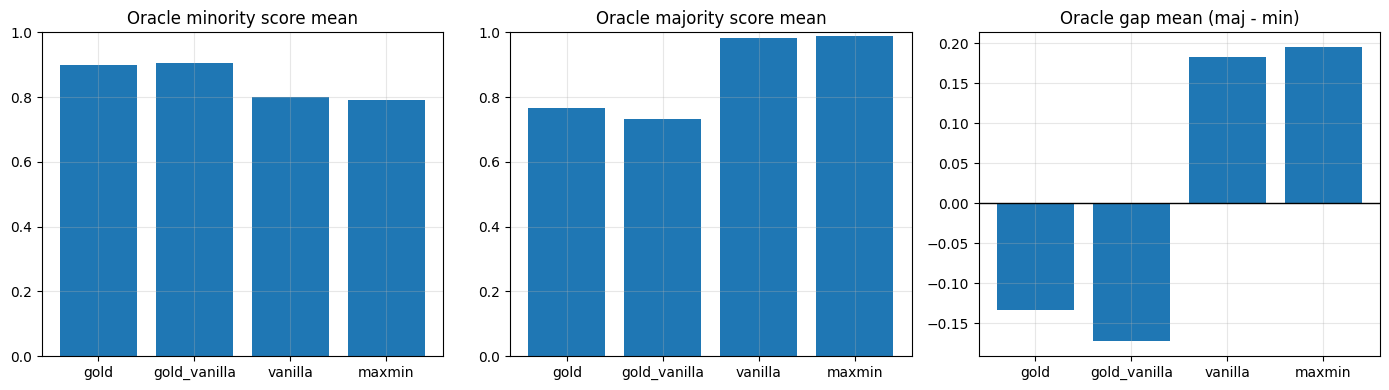

In [4]:
# Optional plotting (safe to skip if matplotlib isn't installed)

try:
    import matplotlib.pyplot as plt
except Exception as e:
    print("matplotlib not available:", e)
    plt = None

if plt is not None and rows:
    labels = [r["method"] for r in rows]

    def get_means(field_label):
        return [r[field_label][0] for r in rows]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].bar(labels, get_means("minority_score"))
    axes[0].set_title("Oracle minority score mean")
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, alpha=0.3)

    axes[1].bar(labels, get_means("majority_score"))
    axes[1].set_title("Oracle majority score mean")
    axes[1].set_ylim(0, 1)
    axes[1].grid(True, alpha=0.3)

    axes[2].bar(labels, get_means("gap(maj-min)"))
    axes[2].set_title("Oracle gap mean (maj - min)")
    axes[2].axhline(0, color="black", linewidth=1)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


### Next: validate MaxMin selection vs oracle (optional)

If you want to reproduce the earlier diagnostic for seed 43 α=1.0:

```bash
python3 -m src.imdb.diagnostics.compare_group_reward_scales \
  --user_id mxcui --seed 43 --proportion 0.2 --alpha 1.0 \
  --max_samples 5000 --batch_size 32 --text_mode completion_only \
  --include_gold --gold_use_dataset_columns
```

If MaxMin still selects `majority` as worst ~100% of the time while oracle selects `minority`, that’s a strong signal the learned-RM selection is not matching the intended objective.


## Validation A — RM preference accuracy on the training preference dataset

This runs the built-in diagnostic on the preference dataset:
- `{USER_ID}/gpt2-imdb-seed{SEED}-prop{PROPORTION}-alpha{ALPHA}`

It checks, per group:
- **RM preference accuracy**: fraction where `RM(chosen) > RM(rejected)`
- **Gold consistency**: fraction where `gold_score(chosen) >= gold_score(rejected)`
- **Gold tie rate** (important for minority at α=1.0)


In [11]:
import os
import sys
import subprocess
from pathlib import Path
from shlex import quote

def find_project_root(start: Path) -> Path:
    """Walk up from start until we find a dir containing both 'src/imdb' and 'notebooks'."""
    for parent in [start, *start.parents]:
        if (parent / "src" / "imdb").exists() and (parent / "notebooks").exists():
            return parent
    raise FileNotFoundError(f"Project root not found from {start}")

project_root = find_project_root(Path.cwd())
script_path = project_root / "src" / "imdb" / "diagnostics" / "compare_group_reward_scales.py"

env = os.environ.copy()
env["PYTHONPATH"] = str(project_root) + (os.pathsep + env["PYTHONPATH"] if env.get("PYTHONPATH") else "")

cmd = [
    sys.executable,
    str(script_path),
    "--user_id", USER_ID,
    "--seed", str(SEED),
    "--proportion", str(PROPORTION),
    "--alpha", str(ALPHA),
    # Keep the eval-generation part small; we're mainly interested in preference dataset here
    "--max_samples", "5000",
    "--batch_size", "32",
    "--text_mode", "completion_only",
    "--include_gold",
    # Preference dataset evaluation
    "--eval_preference_dataset",
    "--pref_max_samples", "5000",
    "--pref_batch_size", "32",
]

print("Running:")
print(" ".join(quote(c) for c in cmd))
print()
res = subprocess.run(cmd, cwd=str(project_root), env=env, capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print("\n[stderr]\n")
    print(res.stderr)
    raise RuntimeError(f"Preference validation failed with exit code {res.returncode}")


Running:
/home/mx/fairness-rlhf/venv/bin/python /home/mx/fairness-rlhf/src/imdb/diagnostics/compare_group_reward_scales.py --user_id mxcui --seed 43 --proportion 0.2 --alpha 1.0 --max_samples 5000 --batch_size 32 --text_mode completion_only --include_gold --eval_preference_dataset --pref_max_samples 5000 --pref_batch_size 32

Dataset: mxcui/maxmin-imdb-ppo-eval-prop0.2-alpha1.0-seed43
Split:   train  rows=24872
Using:   rows=5000  batch_size=32  max_length=256
RM maj:  mxcui/maxmin-imdb-reward-prop0.2-alpha1.0-seed43-majority
RM min:  mxcui/maxmin-imdb-reward-prop0.2-alpha1.0-seed43-minority

=== Raw RM output scale summary (logits) ===
Scored samples: 5000
Majority RM: mean=2.424845 std=0.481618 min=-1.683928 max=3.553453
Minority RM: mean=2.644430 std=0.274456 min=0.299824 max=3.200713

Quantiles (p -> value):
  Majority: {0.0: -1.683928, 0.01: 0.88051, 0.05: 1.569963, 0.5: 2.485579, 0.95: 3.05058, 0.99: 3.212484, 1.0: 3.553453}
  Minority: {0.0: 0.299824, 0.01: 1.918109, 0.05: 2.052

## Validation B — Worst-group selection frequency during MaxMin PPO training

This parses local `wandb/run-*/files/output.log` for the run whose config references the **seed=43 α=1.0 maxmin PPO** model, and summarizes how often `worst_group_name` is `minority` vs `majority`.

If you ran PPO with `WANDB_MODE=offline`, those logs should be present locally.


In [9]:
import re
from collections import Counter

maxmin_model_id = f"{USER_ID}/maxmin-imdb-ppo-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}"
print("Target maxmin PPO model id:", maxmin_model_id)

wandb_dir = project_root / "wandb"
if not wandb_dir.exists():
    raise RuntimeError(f"No wandb directory found at: {wandb_dir}")

# Find candidate runs by scanning config.yaml for the model id
candidates = []
for cfg in wandb_dir.glob("run-*/files/config.yaml"):
    try:
        txt = cfg.read_text(errors="ignore")
    except Exception:
        continue
    if maxmin_model_id in txt:
        candidates.append(cfg)

print(f"Found {len(candidates)} wandb run(s) matching model id")
for c in candidates[:5]:
    print("-", c)

if not candidates:
    print("\nNo matching wandb run found. If PPO ran elsewhere, point this cell to that log file.")
else:
    # Choose the most recently modified config
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    cfg = candidates[0]
    run_dir = cfg.parents[1]  # wandb/run-.../
    out_log = run_dir / "files" / "output.log"
    dbg_log = run_dir / "logs" / "debug.log"

    print("\nUsing run dir:", run_dir)
    print("output.log exists:", out_log.exists())
    print("debug.log exists:", dbg_log.exists())

    # Prefer output.log (contains dict prints with group_selection/*)
    log_path = out_log if out_log.exists() else dbg_log
    if not log_path.exists():
        raise RuntimeError(f"No output/debug log found under: {run_dir}")

    text = log_path.read_text(errors="ignore")

    # Parse group selection occurrences
    name_pat = re.compile(r"group_selection/worst_group_name'?: '([^']+)'\b")
    idx_pat = re.compile(r"group_selection/worst_group_idx'?: (\d+)\b")

    names = name_pat.findall(text)
    idxs = [int(x) for x in idx_pat.findall(text)]

    print("\nParsed entries:")
    print("  worst_group_name count:", len(names))
    print("  worst_group_idx count:", len(idxs))

    if names:
        c = Counter(names)
        total = sum(c.values())
        print("\nWorst group by name:")
        for k, v in c.most_common():
            print(f"  {k:8s}: {v:6d} ({100*v/total:6.2f}%)")

    if idxs:
        c = Counter(idxs)
        total = sum(c.values())
        print("\nWorst group by idx:")
        for k, v in sorted(c.items()):
            print(f"  {k}: {v:6d} ({100*v/total:6.2f}%)")

    # If both exist, sanity check mapping
    if names and idxs:
        print("\nNote: expected mapping for maxmin is idx 0=minority, idx 1=majority")


Target maxmin PPO model id: mxcui/maxmin-imdb-ppo-prop0.2-alpha1.0-seed43
Found 1 wandb run(s) matching model id
- /home/mx/fairness-rlhf/wandb/run-20260218_031504-8thnw1wz/files/config.yaml

Using run dir: /home/mx/fairness-rlhf/wandb/run-20260218_031504-8thnw1wz
output.log exists: True
debug.log exists: True

Parsed entries:
  worst_group_name count: 0
  worst_group_idx count: 782

Worst group by idx:
  0:     11 (  1.41%)
  1:    771 ( 98.59%)


## Baseline — pretrained `lvwerra/gpt2-imdb` (before alignment)

This section estimates the **oracle minority/majority scores** of the *pretrained* policy (no PPO) on the **same prompts** used in each method’s evaluation dataset.

Notes:
- Evaluation datasets here typically store `completion` that already starts with the `prompt`.
- We generate from the pretrained model using a generation config similar to `generate_responses_unified.py`.
- This can be slow; adjust `BASELINE_MAX_SAMPLES` as needed.


In [12]:
import random

import torch
from transformers import AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer

# -------------------------
# Baseline generation config
# -------------------------
BASELINE_MAX_SAMPLES = 1000  # per method
BASELINE_BATCH_SIZE = 32
PROMPT_MAX_LEN = 8
GEN_MAX_LEN = 100  # matches generate_responses_unified.py behavior (max_length=100)

GEN_KWARGS = dict(
    do_sample=True,
    top_k=0,
    temperature=0.7,
    top_p=0.95,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Pretrained policy
base_model_name = "lvwerra/gpt2-imdb"
base_tok = AutoTokenizer.from_pretrained(base_model_name, padding_side="left")
base_tok.pad_token = base_tok.eos_token
base_policy = AutoModelForCausalLM.from_pretrained(base_model_name).to(device)
base_policy.eval()

# Gold scorer
gold_model_name = "lvwerra/distilbert-imdb"
gold_tok = AutoTokenizer.from_pretrained(gold_model_name)
gold_rm = AutoModelForSequenceClassification.from_pretrained(gold_model_name).to(device)
gold_rm.eval()
pos_id = gold_rm.config.label2id["POSITIVE"]

def batched(xs, bs):
    for i in range(0, len(xs), bs):
        yield xs[i : i + bs]


def score_texts_gold(texts):
    enc = gold_tok(
        texts,
        padding=True,
        truncation=True,
        max_length=100,
        return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        out = gold_rm(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
        probs = torch.softmax(out.logits, dim=-1)
        pos = probs[:, pos_id]
        length = enc["attention_mask"].sum(dim=-1).float()
        norm_len = torch.clamp(length / 100.0, 0.0, 1.0)
    pos = pos.detach().float().cpu().tolist()
    length = length.detach().float().cpu().tolist()
    norm_len = norm_len.detach().float().cpu().tolist()
    return pos, length, norm_len


def generate_base_completions(prompts):
    enc = base_tok(
        prompts,
        padding="max_length",
        truncation=True,
        max_length=PROMPT_MAX_LEN,
        return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        out_ids = base_policy.generate(
            input_ids=enc["input_ids"],
            attention_mask=enc["attention_mask"],
            max_length=GEN_MAX_LEN,
            eos_token_id=base_policy.config.eos_token_id,
            pad_token_id=base_tok.pad_token_id,
            **GEN_KWARGS,
        )
    texts = base_tok.batch_decode(out_ids, skip_special_tokens=True)
    return texts


def summarize_oracle(rows):
    # rows: list of dicts with positiveness, normalized_length
    min_s = []
    maj_s = []
    for r in rows:
        p = float(r["positiveness"])
        nl = float(r["normalized_length"])
        ms, js = oracle_scores(p, nl, ALPHA)
        min_s.append(ms)
        maj_s.append(js)
    return {
        "n": len(rows),
        "minority_mean": mean(min_s),
        "minority_std": std(min_s),
        "majority_mean": mean(maj_s),
        "majority_std": std(maj_s),
        "gap_mean": mean([a - b for a, b in zip(maj_s, min_s)]),
        "gap_std": std([a - b for a, b in zip(maj_s, min_s)]),
    }


# Re-load each method dataset (so we have per-method prompt lists)
method_eval = {}
for method_key in METHOD_ORDER:
    ds_id = eval_dataset_id(method_key)
    loaded = load_dataset(ds_id)
    ds = _pick_first_split(loaded)
    method_eval[method_key] = ds

baseline_summaries = {}
aligned_summaries = {}

for method_key in METHOD_ORDER:
    ds = method_eval[method_key]

    # sample prompts
    prompts = [ex["prompt"] for ex in ds]
    # deterministic-ish sampling for reproducibility
    rng = random.Random(SEED)
    if len(prompts) > BASELINE_MAX_SAMPLES:
        idxs = list(range(len(prompts)))
        rng.shuffle(idxs)
        idxs = idxs[:BASELINE_MAX_SAMPLES]
        prompts = [prompts[i] for i in idxs]

    # aligned rows (use the dataset's scored completion)
    aligned_rows = []
    for ex in ds.select(range(min(len(ds), len(prompts)))):
        # NOTE: this uses the dataset ordering for aligned metrics; baseline uses shuffled prompts.
        # For mean-level comparisons this is OK.
        aligned_rows.append(
            {
                "positiveness": to_float(ex.get("positiveness")),
                "normalized_length": to_float(ex.get("normalized_length")),
            }
        )

    aligned_summaries[method_key] = summarize_oracle(aligned_rows)

    # baseline generations + gold scoring
    base_rows = []
    for batch_prompts in batched(prompts, BASELINE_BATCH_SIZE):
        base_texts = generate_base_completions(batch_prompts)
        pos, length, norm_len = score_texts_gold(base_texts)
        for p, nl in zip(pos, norm_len):
            base_rows.append({"positiveness": p, "normalized_length": nl})

    baseline_summaries[method_key] = summarize_oracle(base_rows)

# Print comparison
print("\nPretrained baseline vs aligned (oracle scores on scored outputs)")
for method_key in METHOD_ORDER:
    b = baseline_summaries[method_key]
    a = aligned_summaries[method_key]
    print("\nMethod:", method_key)
    print(f"  baseline n={b['n']}")
    print(f"    minority  {b['minority_mean']:.4f} ± {b['minority_std']:.4f}")
    print(f"    majority  {b['majority_mean']:.4f} ± {b['majority_std']:.4f}")
    print(f"    gap       {b['gap_mean']:.4f} ± {b['gap_std']:.4f}")
    print(f"  aligned  n={a['n']}")
    print(f"    minority  {a['minority_mean']:.4f} ± {a['minority_std']:.4f}  (Δ {a['minority_mean']-b['minority_mean']:+.4f})")
    print(f"    majority  {a['majority_mean']:.4f} ± {a['majority_std']:.4f}  (Δ {a['majority_mean']-b['majority_mean']:+.4f})")
    print(f"    gap       {a['gap_mean']:.4f} ± {a['gap_std']:.4f}  (Δ {a['gap_mean']-b['gap_mean']:+.4f})")


device: cuda


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: lvwerra/gpt2-imdb
Key                              | Status     |  | 
---------------------------------+------------+--+-
transformer.h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Pretrained baseline vs aligned (oracle scores on scored outputs)

Method: gold
  baseline n=1000
    minority  0.1981 ± 0.2827
    majority  0.6083 ± 0.4345
    gap       0.4102 ± 0.4945
  aligned  n=1000
    minority  0.8993 ± 0.0273  (Δ +0.7012)
    majority  0.6978 ± 0.3640  (Δ +0.0895)
    gap       -0.2015 ± 0.3653  (Δ -0.6117)

Method: gold_vanilla
  baseline n=1000
    minority  0.2199 ± 0.2989
    majority  0.6079 ± 0.4360
    gap       0.3879 ± 0.5010
  aligned  n=1000
    minority  0.9047 ± 0.0261  (Δ +0.6848)
    majority  0.6664 ± 0.3632  (Δ +0.0585)
    gap       -0.2384 ± 0.3632  (Δ -0.6263)

Method: vanilla
  baseline n=1000
    minority  0.2273 ± 0.2988
    majority  0.6267 ± 0.4294
    gap       0.3994 ± 0.5069
  aligned  n=1000
    minority  0.7977 ± 0.0564  (Δ +0.5704)
    majority  0.9712 ± 0.1271  (Δ +0.3445)
    gap       0.1735 ± 0.1427  (Δ -0.2259)

Method: maxmin
  baseline n=1000
    minority  0.2178 ± 0.2915
    majority  0.6316 ± 0.4288
    gap       0.4137

## Distribution plots (vanilla vs maxmin): before vs after alignment

Reference comparison: Fig. 3 in MaxMin-RLHF ([`https://arxiv.org/pdf/2402.08925`](https://arxiv.org/pdf/2402.08925)).

We plot distributions for:
- **Positiveness** (higher is better)
- **Conciseness proxy**: `normalized_length` (lower is better; this is what the pipeline computes)

For each method (`vanilla`, `maxmin`):
- **Before alignment**: generations from pretrained `lvwerra/gpt2-imdb`
- **After alignment**: generations from the PPO policy (evaluation dataset)


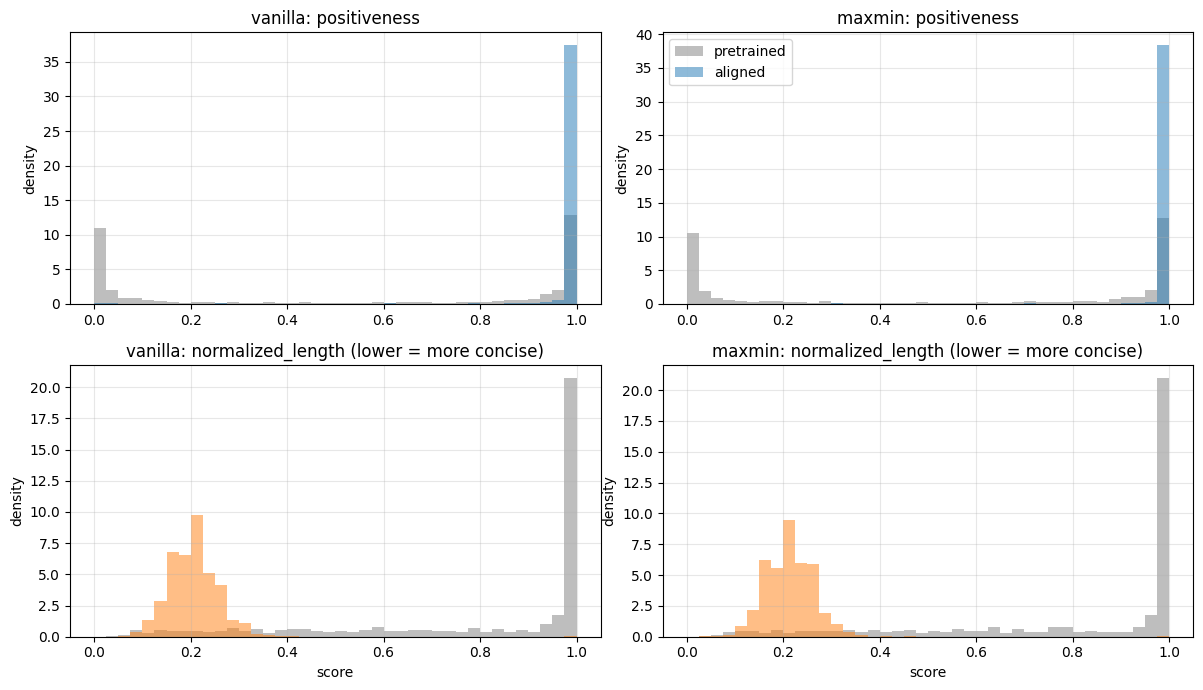

In [13]:
import numpy as np

try:
    import matplotlib.pyplot as plt
except Exception as e:
    print("matplotlib not available:", e)
    plt = None

# Control runtime
DIST_MAX_SAMPLES = 2000
DIST_BATCH_SIZE = 32

# Metrics
def get_aligned_arrays(method_key, max_samples=DIST_MAX_SAMPLES):
    ds_id = eval_dataset_id(method_key)
    ds = _pick_first_split(load_dataset(ds_id))
    n = min(len(ds), max_samples)
    ds = ds.select(range(n))
    pos = np.array([float(x["positiveness"]) for x in ds], dtype=np.float32)
    nlen = np.array([float(x["normalized_length"]) for x in ds], dtype=np.float32)
    prompts = [x["prompt"] for x in ds]
    return prompts, pos, nlen


def get_baseline_arrays(prompts, batch_size=DIST_BATCH_SIZE):
    # Uses the pretrained base_policy + gold scorer from the earlier baseline cell.
    # If not defined (fresh kernel), load them.
    global base_policy, base_tok, gold_rm, gold_tok, pos_id, device

    if "device" not in globals():
        device = "cuda" if torch.cuda.is_available() else "cpu"

    if "base_policy" not in globals() or "base_tok" not in globals():
        base_model_name = "lvwerra/gpt2-imdb"
        base_tok = AutoTokenizer.from_pretrained(base_model_name, padding_side="left")
        base_tok.pad_token = base_tok.eos_token
        base_policy = AutoModelForCausalLM.from_pretrained(base_model_name).to(device)
        base_policy.eval()

    if "gold_rm" not in globals() or "gold_tok" not in globals() or "pos_id" not in globals():
        gold_model_name = "lvwerra/distilbert-imdb"
        gold_tok = AutoTokenizer.from_pretrained(gold_model_name)
        gold_rm = AutoModelForSequenceClassification.from_pretrained(gold_model_name).to(device)
        gold_rm.eval()
        pos_id = gold_rm.config.label2id["POSITIVE"]

    def batched(xs, bs):
        for i in range(0, len(xs), bs):
            yield xs[i : i + bs]

    pos_all = []
    nlen_all = []

    with torch.no_grad():
        for batch_prompts in batched(prompts, batch_size):
            enc = base_tok(
                batch_prompts,
                padding="max_length",
                truncation=True,
                max_length=8,
                return_tensors="pt",
            ).to(device)
            out_ids = base_policy.generate(
                input_ids=enc["input_ids"],
                attention_mask=enc["attention_mask"],
                max_length=100,
                eos_token_id=base_policy.config.eos_token_id,
                pad_token_id=base_tok.pad_token_id,
                do_sample=True,
                top_k=0,
                temperature=0.7,
                top_p=0.95,
            )
            texts = base_tok.batch_decode(out_ids, skip_special_tokens=True)

            genc = gold_tok(
                texts,
                padding=True,
                truncation=True,
                max_length=100,
                return_tensors="pt",
            ).to(device)
            gout = gold_rm(input_ids=genc["input_ids"], attention_mask=genc["attention_mask"])
            probs = torch.softmax(gout.logits, dim=-1)
            pos = probs[:, pos_id]
            length = genc["attention_mask"].sum(dim=-1).float()
            nlen = torch.clamp(length / 100.0, 0.0, 1.0)

            pos_all.extend(pos.detach().float().cpu().tolist())
            nlen_all.extend(nlen.detach().float().cpu().tolist())

    return np.array(pos_all, dtype=np.float32), np.array(nlen_all, dtype=np.float32)


# Collect arrays for vanilla/maxmin
methods_to_plot = ["vanilla", "maxmin"]

data = {}
for m in methods_to_plot:
    prompts, pos_a, nlen_a = get_aligned_arrays(m)
    # Use same prompts for baseline, subsampled to DIST_MAX_SAMPLES already
    pos_b, nlen_b = get_baseline_arrays(prompts)
    data[m] = {
        "baseline": {"pos": pos_b, "nlen": nlen_b},
        "aligned": {"pos": pos_a, "nlen": nlen_a},
    }

# Plot
if plt is not None:
    bins_pos = np.linspace(0, 1, 41)
    bins_nlen = np.linspace(0, 1, 41)

    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="row")

    for j, m in enumerate(methods_to_plot):
        # Positiveness
        ax = axes[0, j]
        ax.hist(data[m]["baseline"]["pos"], bins=bins_pos, density=True, alpha=0.5, label="pretrained", color="tab:gray")
        ax.hist(data[m]["aligned"]["pos"], bins=bins_pos, density=True, alpha=0.5, label="aligned", color="tab:blue")
        ax.set_title(f"{m}: positiveness")
        ax.set_ylabel("density")
        ax.grid(True, alpha=0.3)
        if j == 1:
            ax.legend()

        # Normalized length (conciseness proxy)
        ax = axes[1, j]
        ax.hist(data[m]["baseline"]["nlen"], bins=bins_nlen, density=True, alpha=0.5, label="pretrained", color="tab:gray")
        ax.hist(data[m]["aligned"]["nlen"], bins=bins_nlen, density=True, alpha=0.5, label="aligned", color="tab:orange")
        ax.set_title(f"{m}: normalized_length (lower = more concise)")
        ax.set_xlabel("score")
        ax.set_ylabel("density")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    # Fallback: print means
    for m in methods_to_plot:
        print("\nMethod:", m)
        for stage in ["baseline", "aligned"]:
            pos = data[m][stage]["pos"]
            nlen = data[m][stage]["nlen"]
            print(f"  {stage:8s} pos mean={pos.mean():.4f} std={pos.std(ddof=1):.4f} | nlen mean={nlen.mean():.4f} std={nlen.std(ddof=1):.4f}")


## Replicate Fig. 2-style preference distributions (training preference dataset)

This uses the **preference dataset used to train reward models**:
- `{USER_ID}/gpt2-imdb-seed{SEED}-prop{PROPORTION}-alpha{ALPHA}`

For each group (`minority`=0, `majority`=1) we plot distributions of:
- **Sentiment (positiveness)** for `chosen` vs `rejected`
- **Conciseness proxy (normalized_length)** for `chosen` vs `rejected`

Expected qualitative pattern at α=1.0:
- minority: strong separation in **normalized_length**, overlap in **positiveness**
- majority: strong separation in **positiveness**, overlap in **normalized_length**


Preference dataset: mxcui/gpt2-imdb-seed43-prop0.2-alpha1.0
Rows used: 10000
minority: n=1859
majority: n=8141


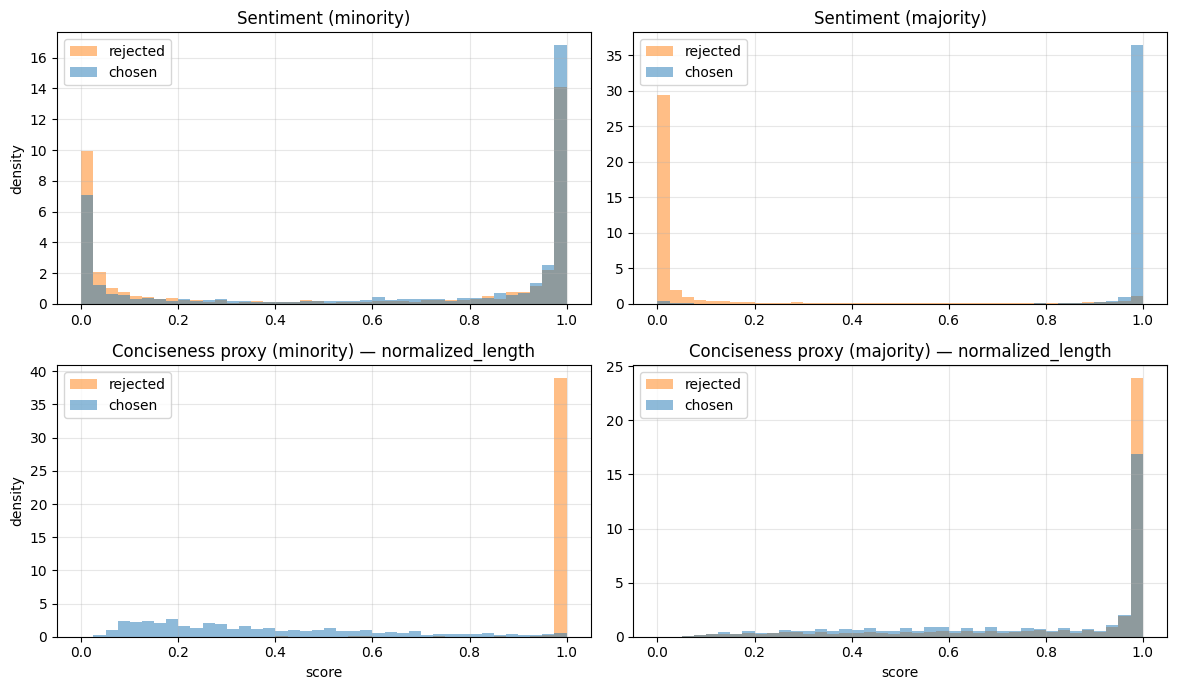

In [14]:
import numpy as np
import torch

try:
    import matplotlib.pyplot as plt
except Exception as e:
    print("matplotlib not available:", e)
    plt = None

PREF_MAX_SAMPLES = 10000
PREF_BATCH_SIZE = 32

pref_id = f"{USER_ID}/gpt2-imdb-seed{SEED}-prop{PROPORTION}-alpha{ALPHA}"
print("Preference dataset:", pref_id)

pref_ds = load_dataset(pref_id, split="train")
# Shuffle to get representative subset
if PREF_MAX_SAMPLES and len(pref_ds) > PREF_MAX_SAMPLES:
    pref_ds = pref_ds.shuffle(seed=SEED).select(range(PREF_MAX_SAMPLES))
print("Rows used:", len(pref_ds))

for col in ("chosen", "rejected", "group_id"):
    if col not in pref_ds.column_names:
        raise RuntimeError(f"Preference dataset missing '{col}'. Have: {pref_ds.column_names}")

# Load gold scorer if needed
if "device" not in globals():
    device = "cuda" if torch.cuda.is_available() else "cpu"

if "gold_rm" not in globals() or "gold_tok" not in globals() or "pos_id" not in globals():
    gold_model_name = "lvwerra/distilbert-imdb"
    gold_tok = AutoTokenizer.from_pretrained(gold_model_name)
    gold_rm = AutoModelForSequenceClassification.from_pretrained(gold_model_name).to(device)
    gold_rm.eval()
    pos_id = gold_rm.config.label2id["POSITIVE"]


def score_texts_for_fig2(texts, batch_size=PREF_BATCH_SIZE):
    pos_all = []
    nlen_all = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = gold_tok(
                batch,
                padding=True,
                truncation=True,
                max_length=100,
                return_tensors="pt",
            ).to(device)
            out = gold_rm(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
            probs = torch.softmax(out.logits, dim=-1)
            pos = probs[:, pos_id]
            length = enc["attention_mask"].sum(dim=-1).float()
            nlen = torch.clamp(length / 100.0, 0.0, 1.0)
            pos_all.extend(pos.detach().float().cpu().tolist())
            nlen_all.extend(nlen.detach().float().cpu().tolist())
    return np.array(pos_all, dtype=np.float32), np.array(nlen_all, dtype=np.float32)


# Collect texts per group and label
by_group = {
    0: {"chosen": [], "rejected": []},
    1: {"chosen": [], "rejected": []},
}
for ex in pref_ds:
    gid = int(ex["group_id"])
    if gid not in by_group:
        continue
    by_group[gid]["chosen"].append(ex["chosen"])
    by_group[gid]["rejected"].append(ex["rejected"])

# Score
fig2 = {}
for gid, gname in [(0, "minority"), (1, "majority")]:
    pos_c, nlen_c = score_texts_for_fig2(by_group[gid]["chosen"])
    pos_r, nlen_r = score_texts_for_fig2(by_group[gid]["rejected"])
    fig2[gname] = {
        "pos_chosen": pos_c,
        "pos_rejected": pos_r,
        "nlen_chosen": nlen_c,
        "nlen_rejected": nlen_r,
        "n": len(by_group[gid]["chosen"]),
    }
    print(f"{gname}: n={fig2[gname]['n']}")

# Plot (2x2)
if plt is not None:
    bins_pos = np.linspace(0, 1, 41)
    bins_nlen = np.linspace(0, 1, 41)

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))

    # (a) Sentiment minority
    ax = axes[0, 0]
    ax.hist(fig2["minority"]["pos_rejected"], bins=bins_pos, density=True, alpha=0.5, label="rejected", color="tab:orange")
    ax.hist(fig2["minority"]["pos_chosen"], bins=bins_pos, density=True, alpha=0.5, label="chosen", color="tab:blue")
    ax.set_title("Sentiment (minority)")
    ax.set_ylabel("density")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # (b) Sentiment majority
    ax = axes[0, 1]
    ax.hist(fig2["majority"]["pos_rejected"], bins=bins_pos, density=True, alpha=0.5, label="rejected", color="tab:orange")
    ax.hist(fig2["majority"]["pos_chosen"], bins=bins_pos, density=True, alpha=0.5, label="chosen", color="tab:blue")
    ax.set_title("Sentiment (majority)")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # (c) Conciseness minority (normalized_length)
    ax = axes[1, 0]
    ax.hist(fig2["minority"]["nlen_rejected"], bins=bins_nlen, density=True, alpha=0.5, label="rejected", color="tab:orange")
    ax.hist(fig2["minority"]["nlen_chosen"], bins=bins_nlen, density=True, alpha=0.5, label="chosen", color="tab:blue")
    ax.set_title("Conciseness proxy (minority) — normalized_length")
    ax.set_xlabel("score")
    ax.set_ylabel("density")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # (d) Conciseness majority
    ax = axes[1, 1]
    ax.hist(fig2["majority"]["nlen_rejected"], bins=bins_nlen, density=True, alpha=0.5, label="rejected", color="tab:orange")
    ax.hist(fig2["majority"]["nlen_chosen"], bins=bins_nlen, density=True, alpha=0.5, label="chosen", color="tab:blue")
    ax.set_title("Conciseness proxy (majority) — normalized_length")
    ax.set_xlabel("score")
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()
else:
    print("matplotlib not available; printing means instead")
    for gname in ("minority", "majority"):
        print("\n", gname)
        print("  pos chosen mean", float(fig2[gname]["pos_chosen"].mean()))
        print("  pos rejected mean", float(fig2[gname]["pos_rejected"].mean()))
        print("  nlen chosen mean", float(fig2[gname]["nlen_chosen"].mean()))
        print("  nlen rejected mean", float(fig2[gname]["nlen_rejected"].mean()))


## Continuous PDF-style plots (KDE) — Fig. 2 / Fig. 3 style

The paper plots smooth density curves. Below we use a simple Gaussian KDE (with boundary reflection for 
\([0,1]\)) to produce continuous PDF-style plots for:
- **Fig. 2-style**: chosen vs rejected (by group) on the preference dataset
- **Fig. 3-style**: pretrained vs aligned (vanilla/maxmin) on eval prompts


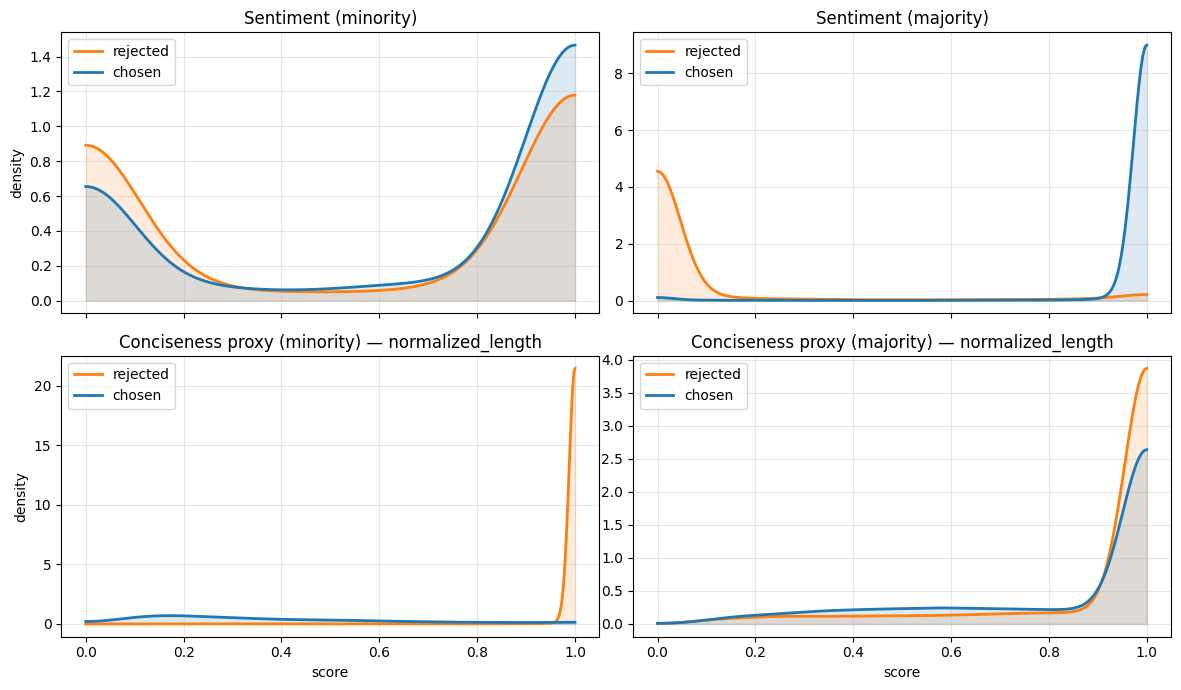

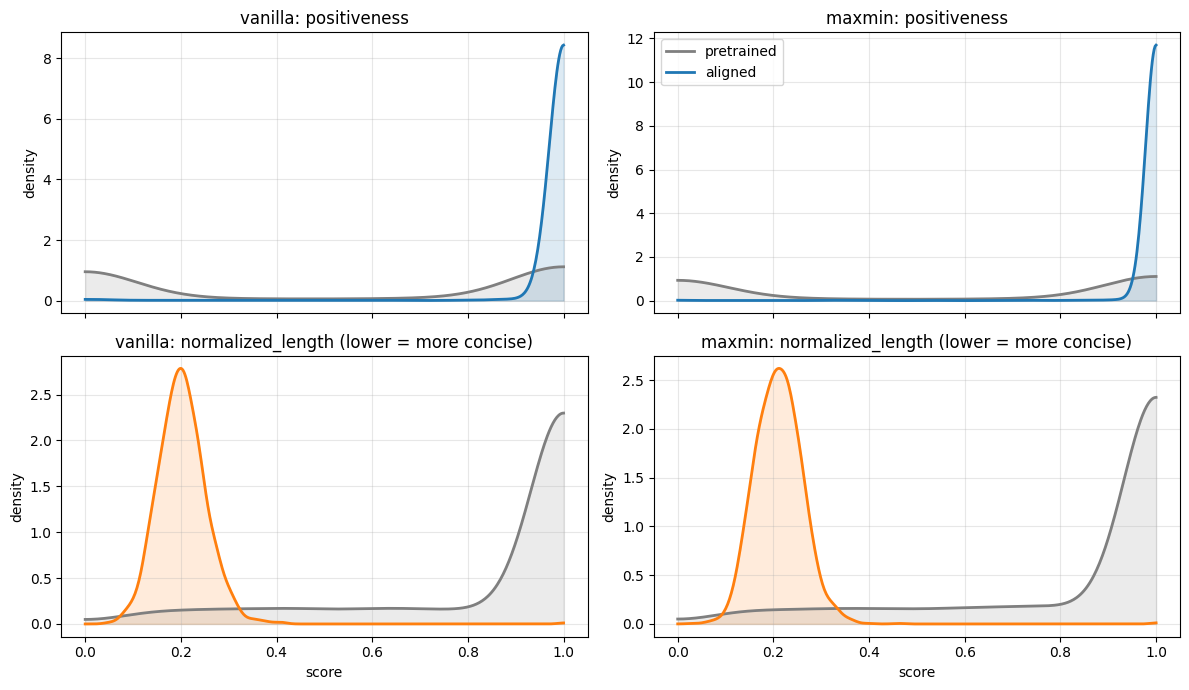

In [15]:
import numpy as np

try:
    import matplotlib.pyplot as plt
except Exception as e:
    print("matplotlib not available:", e)
    plt = None


def kde_gaussian_1d_reflect01(x: np.ndarray, grid: np.ndarray, bw: float | None = None) -> np.ndarray:
    """Gaussian KDE on [0,1] using reflection to reduce boundary bias."""
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.zeros_like(grid, dtype=np.float64)

    # bandwidth: Silverman's rule
    if bw is None:
        std = np.std(x, ddof=1) if x.size > 1 else 0.1
        bw = 1.06 * std * (x.size ** (-1 / 5))
        bw = float(max(bw, 1e-3))

    # Reflection at boundaries 0 and 1
    xr = np.concatenate([x, -x, 2 - x])

    # Compute KDE
    g = grid.astype(np.float64)
    # (m, n)
    z = (g[:, None] - xr[None, :]) / bw
    dens = np.exp(-0.5 * z * z).sum(axis=1) / (xr.size * bw * np.sqrt(2 * np.pi))
    return dens


def plot_kde(ax, x, label, color, bw=None, fill_alpha=0.15, lw=2):
    grid = np.linspace(0, 1, 500)
    dens = kde_gaussian_1d_reflect01(np.asarray(x), grid, bw=bw)
    ax.plot(grid, dens, color=color, lw=lw, label=label)
    ax.fill_between(grid, 0, dens, color=color, alpha=fill_alpha)


# -------------------------
# KDE: Fig. 2-style plots
# -------------------------
if plt is not None and "fig2" in globals():
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

    # sentiment minority
    ax = axes[0, 0]
    plot_kde(ax, fig2["minority"]["pos_rejected"], "rejected", "tab:orange")
    plot_kde(ax, fig2["minority"]["pos_chosen"], "chosen", "tab:blue")
    ax.set_title("Sentiment (minority)")
    ax.set_ylabel("density")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # sentiment majority
    ax = axes[0, 1]
    plot_kde(ax, fig2["majority"]["pos_rejected"], "rejected", "tab:orange")
    plot_kde(ax, fig2["majority"]["pos_chosen"], "chosen", "tab:blue")
    ax.set_title("Sentiment (majority)")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # conciseness minority
    ax = axes[1, 0]
    plot_kde(ax, fig2["minority"]["nlen_rejected"], "rejected", "tab:orange")
    plot_kde(ax, fig2["minority"]["nlen_chosen"], "chosen", "tab:blue")
    ax.set_title("Conciseness proxy (minority) — normalized_length")
    ax.set_xlabel("score")
    ax.set_ylabel("density")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # conciseness majority
    ax = axes[1, 1]
    plot_kde(ax, fig2["majority"]["nlen_rejected"], "rejected", "tab:orange")
    plot_kde(ax, fig2["majority"]["nlen_chosen"], "chosen", "tab:blue")
    ax.set_title("Conciseness proxy (majority) — normalized_length")
    ax.set_xlabel("score")
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()
else:
    print("Skip Fig2-KDE: need matplotlib and to have run the Fig2 scoring cell (fig2 dict).")


# -------------------------
# KDE: Fig. 3-style plots
# -------------------------
if plt is not None and "data" in globals():
    methods_to_plot = ["vanilla", "maxmin"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

    for j, m in enumerate(methods_to_plot):
        # positiveness
        ax = axes[0, j]
        plot_kde(ax, data[m]["baseline"]["pos"], "pretrained", "tab:gray")
        plot_kde(ax, data[m]["aligned"]["pos"], "aligned", "tab:blue")
        ax.set_title(f"{m}: positiveness")
        ax.set_ylabel("density")
        ax.grid(True, alpha=0.3)
        if j == 1:
            ax.legend()

        # normalized length
        ax = axes[1, j]
        plot_kde(ax, data[m]["baseline"]["nlen"], "pretrained", "tab:gray")
        plot_kde(ax, data[m]["aligned"]["nlen"], "aligned", "tab:orange")
        ax.set_title(f"{m}: normalized_length (lower = more concise)")
        ax.set_xlabel("score")
        ax.set_ylabel("density")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("Skip Fig3-KDE: need matplotlib and to have run the before/after cell (data dict).")
